# Lesson 1 — RL, MDP and return

*Chapter I. RL foundations and tabular methods · Section 1 of the lecture notes*

**Foundations:** Silver 1–2; Sutton–Barto Ch. 1, §§3.1–3.4.

> **Learning goal.** Describe a task by state, action, reward and horizon; distinguish observation from state; compute the return and identify the objective.

> **How to read this notebook.** Markdown cells are the lecture, translated to English without changing its content. Boxes that start with **Code** are additions that map the lecture to the code in this folder:
> `returns.py` (Eqs. 1–3), `interaction.py` (agent–environment loop, pipeline, truncation), `observability.py` (observation vs state).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from rlcore import GridWorld, TabularPolicy
from returns import ObjectiveEstimator, discounted_return, returns_to_go
from interaction import (AgentEnvironmentLoop, compare_first_actions, delayed_reward_mdp,
                         first_action_policy, pipeline_demo, truncated_rollout)
from observability import MovingObject, next_observation_table, predictability

## 1. Quick intuition

RL learns to make decisions when actions affect both the current reward and future data. An action with a lower immediate reward may open the way to a better outcome. The **policy** decides behavior; the **value** predicts the long-term outcome; the **model** predicts transitions. An agent does not have to contain all three components. [Silver, Lectures 1–2]

**Prerequisites.** Conditional probability, expectation and summation. When rewards are random, the objective uses an expectation; a single good rollout does not determine the quality of a policy.

## 2. The problem being solved

**Setting.** A finite MDP in Silver is $(\mathcal S, \mathcal A, \mathcal P, \mathcal R, \gamma)$. The Markov condition means that the distribution of the transition and reward, once the current state and action are known, does not need the whole history. A single camera image may lack velocity or occluded objects, so it is not automatically a Markov state.

**Input/output.** When learning online: the transitions $(S_t, A_t, R_{t+1}, S_{t+1})$; the output is usually a policy or a value from which a policy is derived. At use time: from the current state/observation/history to an action. If only a pre-collected dataset is available, move to the offline setting in Section 14.

**Objective and metric.** The objective is to maximize the expected return. The metric can be evaluation return or success; success is not automatically the same as the reward used during training.

> **Code.** `rlcore.TabularMDP` stores $(\mathcal S,\mathcal A,\mathcal P,\mathcal R,\gamma)$: `P[s, a, s']` $=\mathcal P^a_{ss'}$, `R[s, a]` $=\mathcal R^a_s$. `AgentEnvironmentLoop` records exactly the online input $(S_t, A_t, R_{t+1}, S_{t+1})$.

In [2]:
env = GridWorld(["S..",
                 ".#.",
                 "..G"], slip=0.1, gamma=0.9)
print(env)
print("P^a_{ss'} has shape", env.P.shape, "| R^a_s has shape", env.R.shape, "| gamma =", env.gamma)

loop = AgentEnvironmentLoop(env, TabularPolicy.uniform(env.n_states, env.n_actions), np.random.default_rng(0))
for tr in loop.run_episode()[:5]:
    print(f"S_t={env.state_names[tr.state]:6s} A_t={env.action_names[tr.action]:5s} "
          f"R_t+1={tr.reward:+.0f}  S_t+1={env.state_names[tr.next_state]:6s} terminated={tr.terminated}")

GridWorld(n_states=9, n_actions=4, gamma=0.9)
P^a_{ss'} has shape (9, 4, 9) | R^a_s has shape (9, 4) | gamma = 0.9
S_t=(0,0)  A_t=down  R_t+1=-1  S_t+1=(1,0)  terminated=False
S_t=(1,0)  A_t=right R_t+1=-1  S_t+1=(1,0)  terminated=False
S_t=(1,0)  A_t=up    R_t+1=-1  S_t+1=(0,0)  terminated=False
S_t=(0,0)  A_t=up    R_t+1=-1  S_t+1=(0,0)  terminated=False
S_t=(0,0)  A_t=left  R_t+1=-1  S_t+1=(0,0)  terminated=False


**Observation vs state.** The next cell makes the camera example concrete: an object moves on a ring with a hidden velocity $\pm1$ and the camera sees only the position.

> **Code.** `observability.py` measures how predictable the next observation is from the last 1 or 2 frames (1.0 = fully predictable). One frame cannot tell the direction of motion; two frames reveal the velocity.

In [3]:
for h in (1, 2):
    table = next_observation_table(MovingObject(seed=0), history_len=h)
    print(f"history of {h} frame(s): predictability of the next observation = {predictability(table):.2f}")

history of 1 frame(s): predictability of the next observation = 0.53
history of 2 frame(s): predictability of the next observation = 0.89


## 3. Core idea and formulas

$$G_t = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1}. \tag{1}$$

**From time $t$ on, what do we actually receive?** $G_t$ adds up all the remaining rewards of the episode, but the farther a reward is, the more times it is multiplied by $\gamma$. The first term is $R_{t+1}$, the next one is $\gamma R_{t+2}$; so $k$ counts the distance from now, not absolute time. $T-t$ is the number of remaining steps. For a continuing task, the sum extends to infinity; bounded rewards and $\gamma<1$ keep the sum finite.

$\gamma$ close to 1 keeps the weight of distant rewards relatively large; a small $\gamma$ makes them matter less. A finite task can choose $\gamma = 1$. Discounting is applied over time, not as a separate coefficient for each kind of outcome.

> **Code.** `discounted_return(rewards, gamma)` is Eq. (1) read forward. `rewards[k]` stores $R_{t+k+1}$.

In [4]:
rewards = [1, 0, 4]
for gamma in (1.0, 0.9, 0.5, 0.0):
    weights = [gamma**k for k in range(len(rewards))]
    print(f"gamma={gamma:3.1f}  weights gamma^k = {np.round(weights, 3)}  ->  G_0 = {discounted_return(rewards, gamma):.3f}")

gamma=1.0  weights gamma^k = [1. 1. 1.]  ->  G_0 = 5.000
gamma=0.9  weights gamma^k = [1.   0.9  0.81]  ->  G_0 = 4.240
gamma=0.5  weights gamma^k = [1.   0.5  0.25]  ->  G_0 = 2.000
gamma=0.0  weights gamma^k = [1. 0. 0.]  ->  G_0 = 1.000


$$J(\theta) = \mathbb E_{\pi_\theta}[G_0]. \tag{2}$$

One run gives one $G_0$; running again can give a different result. $J(\theta)$ takes the theoretical average of those outcomes when using the policy $\pi_\theta$. The expectation covers the initial state, the sampled actions and the randomness of the environment. **What are we optimizing?** Choose the parameter $\theta$ so that $J$ is larger, not merely make one particular trajectory very good. The average return over many rollouts is one way to estimate $J$.

> **Code.** `ObjectiveEstimator` averages $G_0$ over independent rollouts. Single rollouts spread widely; the average settles as the number of rollouts grows.

    1 rollouts: J ~= -9.750 +- nan (n=1)
   10 rollouts: J ~= -8.537 +- 0.746 (n=10)
  100 rollouts: J ~= -8.786 +- 0.147 (n=100)


 1000 rollouts: J ~= -8.518 +- 0.053 (n=1000)


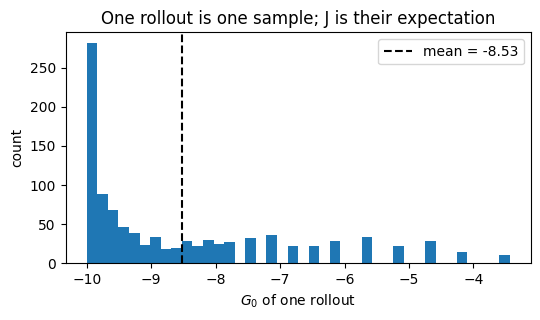

In [5]:
estimator = ObjectiveEstimator(env)
uniform = TabularPolicy.uniform(env.n_states, env.n_actions)
rng = np.random.default_rng(0)
for n in (1, 10, 100, 1000):
    print(f"{n:5d} rollouts: {estimator.estimate(uniform, n, rng)}")

est = estimator.estimate(uniform, 1000, np.random.default_rng(1))
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(est.returns, bins=40)
ax.axvline(est.mean, color="k", ls="--", label=f"mean = {est.mean:.2f}")
ax.set_xlabel("$G_0$ of one rollout"); ax.set_ylabel("count"); ax.legend()
ax.set_title("One rollout is one sample; J is their expectation")
plt.show()

$$G_t = R_{t+1} + \gamma G_{t+1}. \tag{3}$$

Split the reward sequence into **the step just taken** and **the remainder**. $R_{t+1}$ is the step just taken; $G_{t+1}$ has already added up the remainder from the next time step. Multiply that part by $\gamma$ to shift all of it back one step. For example, if the next reward is $1$ and the return afterwards is $4$ with $\gamma = 0.9$, then $G_t = 4.6$. At the terminal, $G_T = 0$. This is an identity about returns, not yet an update rule for value.

> **Code.** `returns_to_go` uses Eq. (3) backwards from $G_T = 0$, so all $G_0,\dots,G_{T-1}$ cost one pass. It agrees with Eq. (1) at every $t$.

In [6]:
print("G_t with R_{t+1} = 1, G_{t+1} = 4, gamma = 0.9:", returns_to_go([1, 4], 0.9)[0])

long_rewards = np.random.default_rng(0).normal(size=50)
by_recursion = returns_to_go(long_rewards, 0.9)
by_definition = [discounted_return(long_rewards[t:], 0.9) for t in range(50)]
print("Eq. (3) == Eq. (1) at every t:", np.allclose(by_recursion, by_definition))

G_t with R_{t+1} = 1, G_{t+1} = 4, gamma = 0.9: 4.6
Eq. (3) == Eq. (1) at every t: True


## 4. Example and pipeline

The rewards of a three-step episode are $1, 0, 4$, $\gamma = 0.9$. Then $G_0 = 1 + 0.9\cdot 0 + 0.9^2\cdot 4 = 4.24$; $G_1 = 3.6$; $G_2 = 4$. If there is an action that ends immediately with reward $3$, it is better at the first step in terms of immediate reward but worse in terms of return in this example.

1. **Data:** The agent chooses an action, the environment generates the next observation and reward.
2. **Learning:** Collect transitions/trajectories; the algorithm will create targets and update the policy/value/model.
3. **Use and evaluation:** The policy chooses actions with the information truly available at deployment; measure return on separate evaluation rollouts.

> **Code.** `delayed_reward_mdp()` builds this example as an MDP: action `go` earns $1, 0, 4$; action `stop` earns $3$ and ends.

In [7]:
print("returns of the episode 1, 0, 4:", returns_to_go([1, 0, 4], 0.9))
for action, res in compare_first_actions(0.9).items():
    print(f"first action {action!r:6s}: immediate reward = {res['immediate_reward']:.0f}, return G_0 = {res['return_G0']:.2f}")

returns of the episode 1, 0, 4: [4.24 3.6  4.  ]
first action 'go'  : immediate reward = 1, return G_0 = 4.24
first action 'stop': immediate reward = 3, return G_0 = 3.00


> **Code.** The pipeline on the small grid: step 1 collects data with the agent–environment loop, step 3 evaluates on separate rollouts with their own random stream. Step 2 (learning) is what Lessons 2–6 add.

In [8]:
print(pipeline_demo(env, uniform, n_eval=200))

{'collected_transitions': 36, 'eval_mean_return': -8.37504888604807, 'eval_std_return': 1.7461536686847012}


## 5. Comparison, limits and applications

Supervised learning usually receives a target label for each input; RL receives an evaluative signal about consequences, often delayed. Planning uses a model to compute actions; learning uses data to improve the unknown components. Robot navigation is an illustrative example: observations from sensors, actions are motion commands, the reward is tied to the task, the metric is success/collision/return. The reward being optimized may not fully reflect the real objective.

## 6. Exercises

1. An episode has rewards $2, -1, 3$, $\gamma = 0.5$: compute $G_0, G_1$.
2. Why might an image of the current position not be enough for a motion-control problem?
3. If the simulator stops because of a run limit, is that necessarily a terminal of the task?

> **Code.** Try each question before opening the answers. The cells below check exercises 1 and 3.

In [9]:
# Exercise 1
print("G_0, G_1 =", returns_to_go([2, -1, 3], 0.5)[:2])

# Exercise 3: a time limit cuts the episode (truncated) although no terminal state was reached
traj = truncated_rollout(env, uniform, time_limit=3)
print(f"length={len(traj)}, terminated={traj.terminated}, truncated={traj.truncated}")

G_0, G_1 = [2.25 0.5 ]
length=3, terminated=False, truncated=True


<details>
<summary><b>Answers (Appendix A)</b></summary>

(1) $G_0 = 2 - 0.5 + 0.25\cdot 3 = 2.25$, $G_1 = -1 + 0.5\cdot 3 = 0.5$. (2) The same position can have a different velocity or hidden state; the consequences of an action differ even though the present looks the same. (3) No: a computational cutoff may just be a truncation. If the horizon limit is part of the task, the remaining time may also need to be included in the state.
</details>

## 7. Remember and read further

Reward is one-step feedback; return is the sum over time; the objective is an expectation over trajectories. The state must be sufficient for decisions. Read Silver 1–2 and Sutton–Barto §§3.1–3.4; move on to value in Section 2.